## Kaiser-Squires vs NPE on the DC2 test region

Compares the NPE posterior-mean convergence maps with Kaiser-Squires (KS) reconstructions on the same tiles, redshift bins and targets (the 56 x 56-tile test region of tract 3828).

KS maps come from `images_to_maps/dc2/kaiser_squires.py` on tract 3828's tile grid, extended 40 tiles past every edge so the inversion's edge effects fall outside the test region:

* **KS oracle**: tile-mean true shear of all galaxies (no shape noise), an upper bound for the inversion alone.
* **KS, perfect shapes**: tile-mean lensed ellipticity of selected detected galaxies with their exact rendered intrinsic shapes (no measurement noise, PSF or calibration error), binned by true redshift. Two selections: `all_detected` (every galaxy matched to a detected object; an optimistic bound) and `metacal` (exactly the galaxies used by the metacal map below, so that the two maps differ only in how shapes are measured).
* **KS, metacal shapes (calibrated)**: DESC's DR6-v2 metacalibration shear estimates for galaxies matched to detected objects passing the general metacal cuts (unflagged, 10 < S/N < 1000, T/T_PSF > 0.5, T < 10 arcsec$^2$, not large-and-faint), binned by true redshift, following Sheldon & Huff (2017) and the DES Y3 recipe (Gatti et al. 2021): (S/N, T/T_PSF)-cell inverse-variance weights, per-bin weighted shear + selection response, element-wise response correction, weighted tile means, per-bin mean-shear subtraction, and removal of per-bin multiplicative and additive biases fitted against the true shear of galaxies outside the test region.

Each KS map is smoothed with a Gaussian whose width is chosen per map and bin by maximum Pearson correlation with the true convergence on the validation tiles (candidates 0-32 tiles), then frozen for the test region, following the usual practice for KS baselines (e.g. Remy et al. 2023, who tune the KS smoothing on simulations). The NPE posterior means are not smoothed.

Generate the KS inputs from the repo root (`OUT=images_to_maps/results/dc2/kaiser_squires`):
```
python -m images_to_maps.dc2.kaiser_squires --output $OUT/oracle_tract3828_pad40.npz
python -m images_to_maps.dc2.kaiser_squires --shear-source lensed_ellipticity --selection all_detected --output $OUT/perfectshape_all_detected_tract3828_pad40.npz
python -m images_to_maps.dc2.kaiser_squires --shear-source lensed_ellipticity --selection metacal --output $OUT/perfectshape_metacal_tract3828_pad40.npz
python -m images_to_maps.dc2.kaiser_squires --shear-source metacal --selection metacal --output $OUT/metacal_tract3828_pad40.npz
```

**Network.** The NPE maps come from the paper network (`ch_max=1024`, `initial_downsample=false`, `more_up_layers=true`, epoch 63 of run `padded_nanpsf_1024_False_True_v2`, checkpoint `checkpoints/trained_encoder.ckpt`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from hydra import compose, initialize
from hydra.utils import instantiate
from matplotlib.lines import Line2D
from scipy.ndimage import gaussian_filter
from scipy.signal.windows import tukey

import lightning as L

from images_to_maps.dc2.stitch_npe import predict_crop_interiors, stitch_interiors

plt.rcParams["font.family"] = "serif"

In [2]:
# Paper network, epoch 63 of run padded_nanpsf_1024_False_True_v2
ckpt = "checkpoints/trained_encoder.ckpt"
network_overrides = [
    "encoder.ch_max=1024",
    "encoder.initial_downsample=false",
    "encoder.more_up_layers=true",
    # the two-tract split this checkpoint was trained on (the config now has the four-tract split)
    "surveys.dc2.tracts=[3828,3829]",
    "surveys.dc2.split_regions.test=[{tract:3828,rows:[0,13],cols:[13,26]}]",
    "surveys.dc2.split_regions.val=[{tract:3828,rows:[0,19],cols:[7,26]}]",
]
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

ks_dir = "../../results/dc2/kaiser_squires"
selections = {"all_detected": "all detected", "metacal": "metacal selection"}
sigmas = (0, 0.5, 1, 1.5, 2, 3, 4, 5, 6, 8, 10, 12, 16, 20, 24, 32)  # candidate KS smoothing widths, in tiles
num_bins = 4

with initialize(config_path="../", version_base=None):
    cfg = compose(
        "config_train_npe",
        ["train.pretrained_weights=" + ckpt, *network_overrides],
    )

seed = L.seed_everything(cfg.train.seed)

Seed set to 123123


**Load the KS maps and define the test and validation tiles on the extended grid:**

In [3]:
oracle = dict(np.load(f"{ks_dir}/oracle_tract3828_pad40.npz"))
perfect = {s: dict(np.load(f"{ks_dir}/perfectshape_{s}_tract3828_pad40.npz")) for s in selections}
metacal = dict(np.load(f"{ks_dir}/metacal_tract3828_pad40.npz"))
assert np.array_equal(metacal["count"], perfect["metacal"]["count"])  # paired: same galaxies per tile

row0, col0 = int(oracle["row0"]), int(oracle["col0"])
grid_shape = oracle["kappa_ks"].shape[1:]
tile_row = np.arange(grid_shape[0])[:, None] + row0  # tract tile indices
tile_col = np.arange(grid_shape[1])[None, :] + col0

# test = crop rows 0-13, cols 13-26; val = crop rows 0-19, cols 7-26 minus test (4 tiles per crop)
test = (tile_row >= 0) & (tile_row < 56) & (tile_col >= 52) & (tile_col < 108)
val = (tile_row >= 0) & (tile_row < 80) & (tile_col >= 28) & (tile_col < 108) & ~test
assert test.sum() == 56 * 56 and val.sum() == 80 * 80 - 56 * 56

kappa_true = oracle["convergence_true"]
for s, d in {**perfect, "metacal shapes": metacal}.items():
    assert np.array_equal(d["convergence_true"], kappa_true, equal_nan=True), s
print("grid", grid_shape, "origin tile", (row0, col0))
print("metacal: weighted response per bin (R11, R22):", np.round(np.stack([
    (metacal["R_shear"] + metacal["R_select"])[:, 0, 0], (metacal["R_shear"] + metacal["R_select"])[:, 1, 1]], 1), 3).tolist())
print("metacal: m per bin (g1, g2), fitted outside the test region:", np.round(metacal["m"], 3).tolist(),
      "+-", np.round(metacal["m_err"], 3).tolist())

grid (188, 188) origin tile (-40, -40)
metacal: weighted response per bin (R11, R22): [[0.787, 0.79], [0.744, 0.749], [0.692, 0.699], [0.62, 0.618]]
metacal: m per bin (g1, g2), fitted outside the test region: [[-0.149, 0.123], [-0.124, -0.12], [-0.016, -0.091], [-0.318, -0.312]] +- [[0.088, 0.087], [0.059, 0.058], [0.052, 0.053], [0.054, 0.058]]


**NPE posterior means on the interior tiles of the test crops:**

In [4]:
data_source = instantiate(cfg.train.data_source)
data_source.setup("test")
test_dl = data_source.test_dataloader()

encoder = instantiate(cfg.encoder).to(device)
encoder_state_dict = torch.load(cfg.train.pretrained_weights, map_location=device)["state_dict"]
encoder.load_state_dict(encoder_state_dict, strict=True)
encoder = encoder.eval()

out = predict_crop_interiors(encoder, test_dl, device)


def on_grid(key):
    """Stitch a per-crop field and place it on the extended KS grid (NaN outside test)."""
    stitched = stitch_interiors(out[key], out["positions"]).permute(2, 0, 1).numpy()
    full = np.full((num_bins, *grid_shape), np.nan)
    full[:, test] = stitched.reshape(num_bins, -1)
    return full


kappa_npe = on_grid("convergence_pred")
ra, dec = on_grid("ra"), on_grid("dec")
assert np.allclose(on_grid("convergence_true")[:, test], kappa_true[:, test], atol=1e-6)

**Metrics.** Centred RMSE and Pearson $r$ over the test tiles (each map's own mean removed, since KS cannot recover the mean convergence), and $r(\ell)$ of the $56 \times 56$ test block, computed exactly as in `crosscorrelation.ipynb`: each map's window-weighted mean is subtracted, the map is multiplied by a 2D Tukey window ($\alpha = 0.1$) so that the FFT does not see jumps between opposite edges, and the cross- and auto-spectra are binned in the same log-spaced $\ell$ bins. The same window is applied to every map. $r(\ell)$ uses unsmoothed maps: a Gaussian smoothing multiplies each Fourier mode by a factor that depends only on $\ell$, which nearly cancels in $r(\ell)$, while on a cut-out it would mix in power from outside the test block.

In [5]:
def smooth(m, sigma):
    return m if sigma == 0 else gaussian_filter(m, sigma)


def centred(m, mask):
    return m[mask] - m[mask].mean()


def centred_rmse(p, t, mask=test):
    return np.sqrt(np.mean((centred(p, mask) - centred(t, mask)) ** 2))


def pearson(p, t, mask=test):
    return np.corrcoef(p[mask], t[mask])[0, 1]


tile_slen_rad = 0.853 * np.pi / (180 * 60)
k = np.fft.fftfreq(56, d=tile_slen_rad) * 2 * np.pi
ell_mag = np.hypot(*np.meshgrid(k, k))
ell_edges = np.logspace(np.log10(0.9 * 2 * np.pi / (56 * tile_slen_rad)), np.log10(np.pi / tile_slen_rad), 14)
ell_masks = [(ell_mag >= ell_edges[i]) & (ell_mag < ell_edges[i + 1]) for i in range(13)]
keep = [m.sum() >= 10 for m in ell_masks]
ell_masks = [m for m, kp in zip(ell_masks, keep) if kp]
ell_centers = np.sqrt(ell_edges[:-1] * ell_edges[1:])[keep]

# Tukey taper, as in crosscorrelation.ipynb
taper_alpha = 0.1
window = np.outer(tukey(56, taper_alpha), tukey(56, taper_alpha))


def tapered_fft(m):
    return np.fft.fft2(window * (m - np.sum(window * m) / np.sum(window)))


def r_ell(p, t):
    """r(ell) between maps p and t on the 56 x 56 test block (tapered; normalization cancels in r)."""
    fp, ft = tapered_fft(p[test].reshape(56, 56)), tapered_fft(t[test].reshape(56, 56))
    radial = lambda a: np.array([a[m].mean() for m in ell_masks])  # noqa: E731
    return radial(np.real(np.conj(ft) * fp)) / np.sqrt(radial(np.abs(ft) ** 2) * radial(np.abs(fp) ** 2))


def choose_sigma(maps):
    """Per-bin smoothing width maximizing Pearson r with the true convergence on the validation tiles."""
    return [
        sigmas[int(np.argmax([pearson(smooth(maps[b], sg), kappa_true[b], val) for sg in sigmas]))]
        for b in range(num_bins)
    ]


# smoothing chosen per map and bin on the validation tiles (actual shapes), then frozen for the test region
ks_maps = {f"perfect_{s}": d["kappa_ks"] for s, d in perfect.items()}
ks_maps["metacal_cal"] = metacal["kappa_ks_cal"]
ks_sigma = {name: choose_sigma(m) for name, m in ks_maps.items()}
for name, bs in ks_sigma.items():
    print(f"{name:24s} smoothing (tiles) per bin: {bs}" + ("   (grid maximum: no measurable skill)" if max(bs) == sigmas[-1] else ""))

perfect_all_detected     smoothing (tiles) per bin: [2, 1.5, 1, 1]
perfect_metacal          smoothing (tiles) per bin: [3, 2, 2, 1]
metacal_cal              smoothing (tiles) per bin: [3, 3, 2, 1.5]


In [6]:
rows = []


def add(name, maps, sigma=None):
    for b in range(num_bins):
        m = maps[b] if sigma is None else smooth(maps[b], sigma[b])
        rows.append({"method": name, "bin": b + 1, "rmse": centred_rmse(m, kappa_true[b]), "r": pearson(m, kappa_true[b])})


add("KS oracle", oracle["kappa_ks"])
add("NPE posterior mean", kappa_npe)
for s, d in perfect.items():
    add(f"KS perfect, {selections[s]}", d["kappa_ks"], ks_sigma[f"perfect_{s}"])
add("KS metacal, calibrated", metacal["kappa_ks_cal"], sigma=ks_sigma["metacal_cal"])

for name in dict.fromkeys(r["method"] for r in rows):
    rs = [r for r in rows if r["method"] == name]
    line = "  ".join(f"bin{r['bin']}: {r['rmse']:.4f} / {r['r']:.3f}" for r in rs)
    print(f"{name:34s} centred RMSE / r   {line}")

KS oracle                          centred RMSE / r   bin1: 0.0007 / 0.993  bin2: 0.0008 / 0.998  bin3: 0.0009 / 0.998  bin4: 0.0012 / 0.999
NPE posterior mean                 centred RMSE / r   bin1: 0.0044 / 0.642  bin2: 0.0081 / 0.731  bin3: 0.0105 / 0.759  bin4: 0.0164 / 0.701
KS perfect, all detected           centred RMSE / r   bin1: 0.0069 / 0.291  bin2: 0.0094 / 0.630  bin3: 0.0108 / 0.748  bin4: 0.0118 / 0.852
KS perfect, metacal selection      centred RMSE / r   bin1: 0.0077 / 0.065  bin2: 0.0129 / 0.405  bin3: 0.0140 / 0.529  bin4: 0.0179 / 0.685
KS metacal, calibrated             centred RMSE / r   bin1: 0.0111 / -0.002  bin2: 0.0165 / 0.217  bin3: 0.0267 / 0.191  bin4: 0.0598 / 0.209


**Plot settings.** NPE keeps the paper's green; the three KS competitors take the first three slots of a colour-vision-checked categorical palette; the oracle is a gray dashed reference.

In [7]:
axislabelsize = 10
ticklabelsize = 8
fontsize = 12
colors = {
    "npe": "#1c692b",
    "perfect_all_detected": "#2a78d6",
    "perfect_metacal": "#1baf7a",
    "metacal_cal": "#eb6834",
    "oracle": "#7a7974",
}
labels = {
    "npe": "NPE posterior mean",
    "perfect_all_detected": "KS, perfect shapes, all detected",
    "perfect_metacal": "KS, perfect shapes, metacal selection",
    "metacal_cal": "KS, metacal shapes (calibrated)",
    "oracle": "KS, true shear (oracle)",
}
order = ["npe", "perfect_all_detected", "perfect_metacal", "metacal_cal", "oracle"]


def ks_map(key, b, smoothed=True):
    """Bin-b map of a method; KS maps (not the oracle) smoothed at their validation-chosen width if requested."""
    if key == "npe":
        return kappa_npe[b]
    if key == "oracle":
        return oracle["kappa_ks"][b]
    m = metacal["kappa_ks_cal"][b] if key == "metacal_cal" else perfect[key.removeprefix("perfect_")]["kappa_ks"][b]
    return smooth(m, ks_sigma[key][b]) if smoothed else m

extent = [np.nanmax(ra), np.nanmin(ra), np.nanmin(dec), np.nanmax(dec)]
aspect = 1 / np.cos(np.deg2rad(np.nanmean(dec)))


def test_block(m):
    return m[test].reshape(56, 56)

**Convergence maps** (KS maps smoothed at the validation-chosen widths; each map's test-region mean removed; colour scales set by the true $\kappa$):

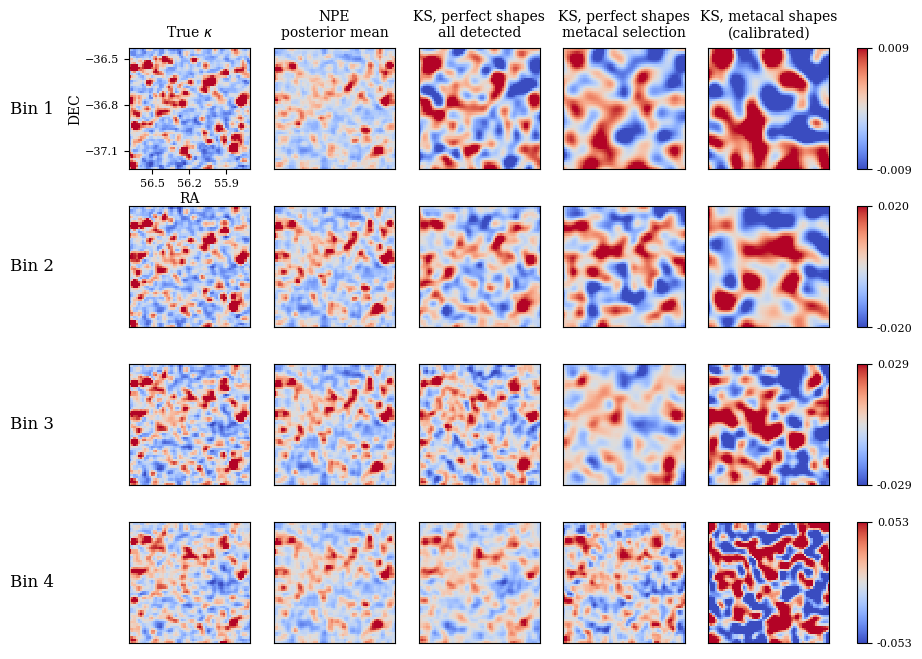

In [8]:
columns = [
    ("True $\\kappa$", lambda b: kappa_true[b]),
    ("NPE\nposterior mean", lambda b: ks_map("npe", b)),
    ("KS, perfect shapes\nall detected", lambda b: ks_map("perfect_all_detected", b)),
    ("KS, perfect shapes\nmetacal selection", lambda b: ks_map("perfect_metacal", b)),
    ("KS, metacal shapes\n(calibrated)", lambda b: ks_map("metacal_cal", b)),
]

fig, ax = plt.subplots(num_bins, len(columns), figsize=(9.2, 7))
row_handles, row_ranges = [], []
for b in range(num_bins):
    truth = test_block(kappa_true[b]) - test_block(kappa_true[b]).mean()
    row_abs = min(abs(np.quantile(truth, 0.001)), abs(np.quantile(truth, 0.999)))
    row_ranges.append(row_abs)
    for j, (_, get) in enumerate(columns):
        m = test_block(get(b))
        h = ax[b, j].imshow(
            m - m.mean(), extent=extent, origin="lower", interpolation="none",
            vmin=-row_abs, vmax=row_abs, cmap="coolwarm",
        )
    row_handles.append(h)

for j, (title, _) in enumerate(columns):
    ax[0, j].set_title(title, fontsize=axislabelsize, pad=8)
ax[0, 0].set_xlabel("RA", fontsize=axislabelsize, labelpad=2)
ax[0, 0].set_ylabel("DEC", fontsize=axislabelsize, labelpad=2)
ax[0, 0].set_xticks([56.5, 56.2, 55.9])
ax[0, 0].set_yticks([-37.1, -36.8, -36.5])
for b in range(num_bins):
    ax[b, 0].text(-0.8, 0.5, f"Bin {b + 1}", transform=ax[b, 0].transAxes, fontsize=fontsize,
                  ha="center", va="center", clip_on=False)
for i, a in enumerate(ax.flat):
    a.set_aspect(aspect)
    if i == 0:
        a.tick_params(axis="both", which="major", labelsize=ticklabelsize)
    else:
        a.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)

fig.subplots_adjust(left=0.175, right=0.945, top=0.90, bottom=0.05, wspace=0.12, hspace=0.3)
for b in range(num_bins):
    pos = ax[b, -1].get_position()
    cbar_ax = fig.add_axes([pos.x1 + 0.030, pos.y0, 0.011, pos.height])
    cbar = fig.colorbar(row_handles[b], cax=cbar_ax)
    cbar.set_ticks([-row_ranges[b], row_ranges[b]])
    cbar.ax.set_yticklabels([f"{-row_ranges[b]:.3f}", f"{row_ranges[b]:.3f}"])
    cbar_ax.tick_params(labelsize=ticklabelsize)

fig.savefig("figures/kaisersquires_convergencemaps.png", dpi=600, transparent=True, bbox_inches="tight", pad_inches=0)

**Cross-correlation coefficient $r(\ell)$ with the true convergence** (unsmoothed maps, tapered as described above; KS lines use the actual DC2 shapes):

r(ℓ), columns = ℓ bins ([ 1027.  1338.  1743.  2270.  2957.  3852.  5018.  6537.  8516. 11093.])
NPE posterior mean
  bin 1: [0.762 0.742 0.698 0.652 0.643 0.701 0.578 0.430 0.259 0.080]
  bin 2: [0.894 0.821 0.746 0.764 0.725 0.769 0.637 0.550 0.352 0.173]
  bin 3: [0.904 0.792 0.850 0.798 0.765 0.778 0.642 0.584 0.354 0.091]
  bin 4: [0.795 0.614 0.786 0.759 0.778 0.755 0.602 0.564 0.338 0.150]
KS, perfect shapes, all detected
  bin 1: [ 0.570  0.726  0.276  0.454  0.142  0.170  0.133  0.101 -0.020  0.036]
  bin 2: [0.827 0.853 0.725 0.702 0.689 0.535 0.346 0.407 0.092 0.077]
  bin 3: [0.876 0.945 0.829 0.790 0.713 0.723 0.606 0.456 0.175 0.038]
  bin 4: [0.964 0.879 0.957 0.925 0.861 0.877 0.732 0.681 0.288 0.024]
KS, perfect shapes, metacal selection
  bin 1: [ 0.142  0.360  0.084  0.311  0.036  0.142  0.147  0.026 -0.028 -0.014]
  bin 2: [5.176e-01 6.005e-01 3.632e-01 4.998e-01 5.187e-01 3.714e-01 1.609e-01 2.061e-01 3.974e-04 5.905e-02]
  bin 3: [0.715 0.831 0.612 0.475 0.450 0.4

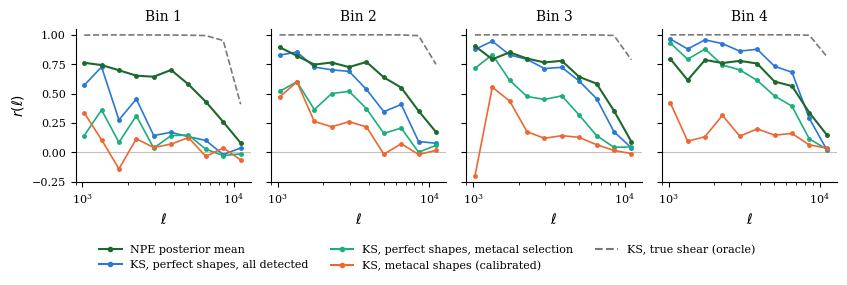

In [9]:
fig, ax = plt.subplots(1, num_bins, figsize=(8.5, 2.6), sharey=True)
r_ell_all = {key: np.array([r_ell(ks_map(key, b, smoothed=False), kappa_true[b]) for b in range(num_bins)]) for key in order}
for b in range(num_bins):
    a = ax[b]
    a.axhline(0, color="#c3c2b7", linewidth=0.8, zorder=0)
    for key in order:
        if key == "oracle":
            a.plot(ell_centers, r_ell_all[key][b], color=colors[key], linestyle="--", linewidth=1.2, zorder=1)
        else:
            a.plot(ell_centers, r_ell_all[key][b], color=colors[key], marker="o", markersize=2.5,
                   linewidth=1.5 if key == "npe" else 1.2, zorder=4 if key == "npe" else 3)
    a.set_xscale("log")
    a.set_xlim(900, 13000)
    a.set_ylim(-0.25, 1.05)
    a.set_title(f"Bin {b + 1}", fontsize=axislabelsize)
    a.set_xlabel(r"$\ell$", fontsize=axislabelsize)
    a.tick_params(axis="both", which="major", labelsize=ticklabelsize)
    a.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel(r"$r(\ell)$", fontsize=axislabelsize)

handles = [Line2D([], [], color=colors[key], linewidth=1.5, linestyle="--" if key == "oracle" else "-",
                  marker=None if key == "oracle" else "o", markersize=3)
           for key in order]
fig.legend(handles, [labels[key] for key in order],
           loc="lower center", ncol=3, frameon=False, fontsize=ticklabelsize, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout(rect=(0, 0.05, 1, 1))

fig.savefig("figures/kaisersquires_crosscorrelation_ell.png", dpi=600, transparent=True, bbox_inches="tight", pad_inches=0)

print(f"r(ℓ), columns = ℓ bins ({np.array2string(ell_centers, precision=0)})")
for key in order:
    print(labels[key])
    for b in range(num_bins):
        print(f"  bin {b + 1}: {np.array2string(r_ell_all[key][b], precision=3, floatmode='fixed', max_line_width=200)}")

**Per-tile Pearson $r$ with the true convergence** (KS maps smoothed at the validation-chosen widths):

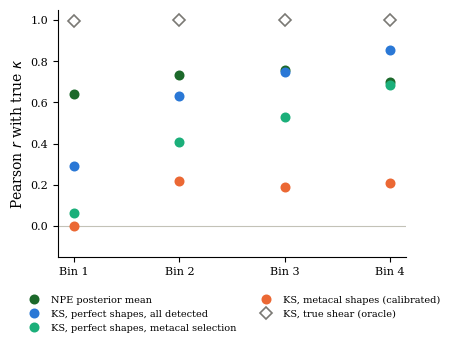

In [10]:
fig, a = plt.subplots(figsize=(4.6, 3.6))
bins = np.arange(1, num_bins + 1)
for key in order:
    r = [pearson(ks_map(key, b), kappa_true[b]) for b in range(num_bins)]
    a.plot(bins, r, linestyle="none", marker="D" if key == "oracle" else "o", markersize=6,
           color="white" if key == "oracle" else colors[key], markeredgecolor=colors[key], markeredgewidth=1.2,
           label=labels[key])
a.axhline(0, color="#c3c2b7", linewidth=0.8, zorder=0)
a.set_xticks(bins, [f"Bin {b}" for b in bins])
a.set_ylim(-0.15, 1.05)
a.set_ylabel(r"Pearson $r$ with true $\kappa$", fontsize=axislabelsize)
a.tick_params(axis="both", which="major", labelsize=ticklabelsize)
a.spines[["top", "right"]].set_visible(False)
a.legend(frameon=False, fontsize=ticklabelsize - 1, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.tight_layout()

fig.savefig("figures/kaisersquires_pearson.png", dpi=600, transparent=True, bbox_inches="tight", pad_inches=0)